In [1]:
import torch
from torch import nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split, Subset

MEDIA = [0.485, 0.456, 0.406]
DESVIO = [0.229, 0.224, 0.225]

transformacion_simple = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIO),
])

transformacion_aumento = transforms.Compose([
    transforms.RandomResizedCrop(128, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIO),
])

datos_simple = datasets.ImageFolder("../data/tomate", transform=transformacion_simple)
datos_aumento = datasets.ImageFolder("../data/tomate", transform=transformacion_aumento)

generador = torch.Generator().manual_seed(42)
entreno, validacion, prueba = random_split(datos_simple, [0.8, 0.1, 0.1], generator=generador)
entreno_aumento = Subset(datos_aumento, entreno.indices)

cargador_entreno = DataLoader(entreno_aumento, batch_size=32, shuffle=True)
cargador_validacion = DataLoader(validacion, batch_size=32)
cargador_prueba = DataLoader(prueba, batch_size=32)

print(len(entreno_aumento), len(validacion), len(prueba))

12809 1601 1601


#  La red preentrenada

In [2]:
red = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for parametro in red.parameters():
    parametro.requires_grad = False

red.fc = nn.Linear(512, 10)

total = sum(p.numel() for p in red.parameters())
entrenables = sum(p.numel() for p in red.parameters() if p.requires_grad)
print(f"Pesos totales: {total:,}")
print(f"Pesos que se entrenan: {entrenables:,}")

Pesos totales: 11,181,642
Pesos que se entrenan: 5,130


# Entrenamiento

In [3]:
import copy

def evaluar(red, cargador):
    red.eval()
    aciertos = 0
    total = 0
    with torch.no_grad():
        for imagenes, etiquetas in cargador:
            salida = red(imagenes)
            aciertos += (salida.argmax(dim=1) == etiquetas).sum().item()
            total += len(etiquetas)
    return aciertos / total


torch.manual_seed(42)
red.fc = nn.Linear(512, 10)
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(red.fc.parameters(), lr=0.001)

EPOCAS = 10
historial = []
mejor_validacion = 0
mejores_pesos = None
mejor_epoca = 0

for epoca in range(EPOCAS):
    red.eval()
    aciertos = 0
    for imagenes, etiquetas in cargador_entreno:
        salida = red(imagenes)
        perdida = criterio(salida, etiquetas)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        aciertos += (salida.argmax(dim=1) == etiquetas).sum().item()

    exactitud_entreno = aciertos / len(entreno_aumento)
    exactitud_validacion = evaluar(red, cargador_validacion)
    historial.append({"epoca": epoca + 1,
                      "entreno": exactitud_entreno,
                      "validacion": exactitud_validacion})
    print(f"Época {epoca + 1}: entreno {exactitud_entreno:.3f}, validación {exactitud_validacion:.3f}")

    if exactitud_validacion > mejor_validacion:
        mejor_validacion = exactitud_validacion
        mejores_pesos = copy.deepcopy(red.state_dict())
        mejor_epoca = epoca + 1

print("Mejor época:", mejor_epoca, "con validación", mejor_validacion)

Época 1: entreno 0.644, validación 0.717
Época 2: entreno 0.759, validación 0.767
Época 3: entreno 0.788, validación 0.775
Época 4: entreno 0.800, validación 0.788
Época 5: entreno 0.805, validación 0.779
Época 6: entreno 0.821, validación 0.782
Época 7: entreno 0.818, validación 0.768
Época 8: entreno 0.820, validación 0.778
Época 9: entreno 0.826, validación 0.794
Época 10: entreno 0.824, validación 0.774
Mejor época: 9 con validación 0.7938788257339163


# Ajuste fino

In [4]:
red.load_state_dict(mejores_pesos)

for parametro in red.layer4.parameters():
    parametro.requires_grad = True

entrenables = [p for p in red.parameters() if p.requires_grad]
print(f"Pesos que se entrenan ahora: {sum(p.numel() for p in entrenables):,}")

optimizador = torch.optim.Adam(entrenables, lr=0.0001)

EPOCAS = 8

for epoca in range(EPOCAS):
    red.eval()
    aciertos = 0
    for imagenes, etiquetas in cargador_entreno:
        salida = red(imagenes)
        perdida = criterio(salida, etiquetas)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        aciertos += (salida.argmax(dim=1) == etiquetas).sum().item()

    exactitud_entreno = aciertos / len(entreno_aumento)
    exactitud_validacion = evaluar(red, cargador_validacion)
    numero = len(historial) + 1
    historial.append({"epoca": numero,
                      "entreno": exactitud_entreno,
                      "validacion": exactitud_validacion})
    print(f"Época {numero}: entreno {exactitud_entreno:.3f}, validación {exactitud_validacion:.3f}")

    if exactitud_validacion > mejor_validacion:
        mejor_validacion = exactitud_validacion
        mejores_pesos = copy.deepcopy(red.state_dict())
        mejor_epoca = numero

print("Mejor época:", mejor_epoca, "con validación", mejor_validacion)

Pesos que se entrenan ahora: 8,398,858
Época 11: entreno 0.830, validación 0.889
Época 12: entreno 0.900, validación 0.883
Época 13: entreno 0.919, validación 0.936
Época 14: entreno 0.929, validación 0.867
Época 15: entreno 0.938, validación 0.913
Época 16: entreno 0.942, validación 0.950
Época 17: entreno 0.945, validación 0.942
Época 18: entreno 0.954, validación 0.955
Mejor época: 18 con validación 0.9550281074328545


# Guardar el MODELO

In [5]:
from sklearn.metrics import classification_report

red.load_state_dict(mejores_pesos)
print("Exactitud en prueba:", evaluar(red, cargador_prueba))

red.eval()
reales = []
predichas = []
with torch.no_grad():
    for imagenes, etiquetas in cargador_prueba:
        predichas.extend(red(imagenes).argmax(dim=1).tolist())
        reales.extend(etiquetas.tolist())
print(classification_report(reales, predichas, target_names=datos_simple.classes))

torch.save(mejores_pesos, "../modelos/red_tomate_resnet.pt")

Exactitud en prueba: 0.9544034978138664
                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot       0.97      0.96      0.97       237
                        Tomato_Early_blight       0.85      0.90      0.87        91
                         Tomato_Late_blight       0.94      0.94      0.94       194
                           Tomato_Leaf_Mold       0.98      0.99      0.98        92
                  Tomato_Septoria_leaf_spot       0.91      0.95      0.93       163
Tomato_Spider_mites_Two_spotted_spider_mite       0.92      0.97      0.94       156
                        Tomato__Target_Spot       0.96      0.88      0.92       138
      Tomato__Tomato_YellowLeaf__Curl_Virus       1.00      0.99      0.99       334
                Tomato__Tomato_mosaic_virus       0.95      0.95      0.95        39
                             Tomato_healthy       0.99      0.97      0.98       157

                       

# CARGAR FOTOS DE INTERNET

In [6]:
from pathlib import Path
from PIL import Image

NOMBRES = [
    "Mancha bacteriana", "Tizón temprano", "Tizón tardío", "Moho de la hoja",
    "Mancha por Septoria", "Arañuela roja", "Mancha diana",
    "Virus del rizado amarillo", "Virus del mosaico", "Hoja sana",
]

for ruta in sorted(Path("../imagenes prueba").iterdir()):
    imagen = Image.open(ruta).convert("RGB")
    x = transformacion_simple(imagen).unsqueeze(0)
    with torch.no_grad():
        probabilidades = torch.softmax(red(x), dim=1)[0]
    clase = probabilidades.argmax().item()
    print(f"{ruta.name}: {NOMBRES[clase]} ({probabilidades[clase]:.0%})")

0h44fai0vgxe1.jpg: Tizón temprano (97%)
Common_Diseases_Leaves.jpg: Tizón temprano (88%)
istockphoto-2239608413-640x640.jpg: Tizón temprano (96%)
tomate-enfermedad-tizon.jpg: Tizón temprano (99%)
VRA.jpg: Tizón temprano (99%)
VRA2.jpg: Tizón tardío (91%)


# TABLA DE LOS 4 MODELOS

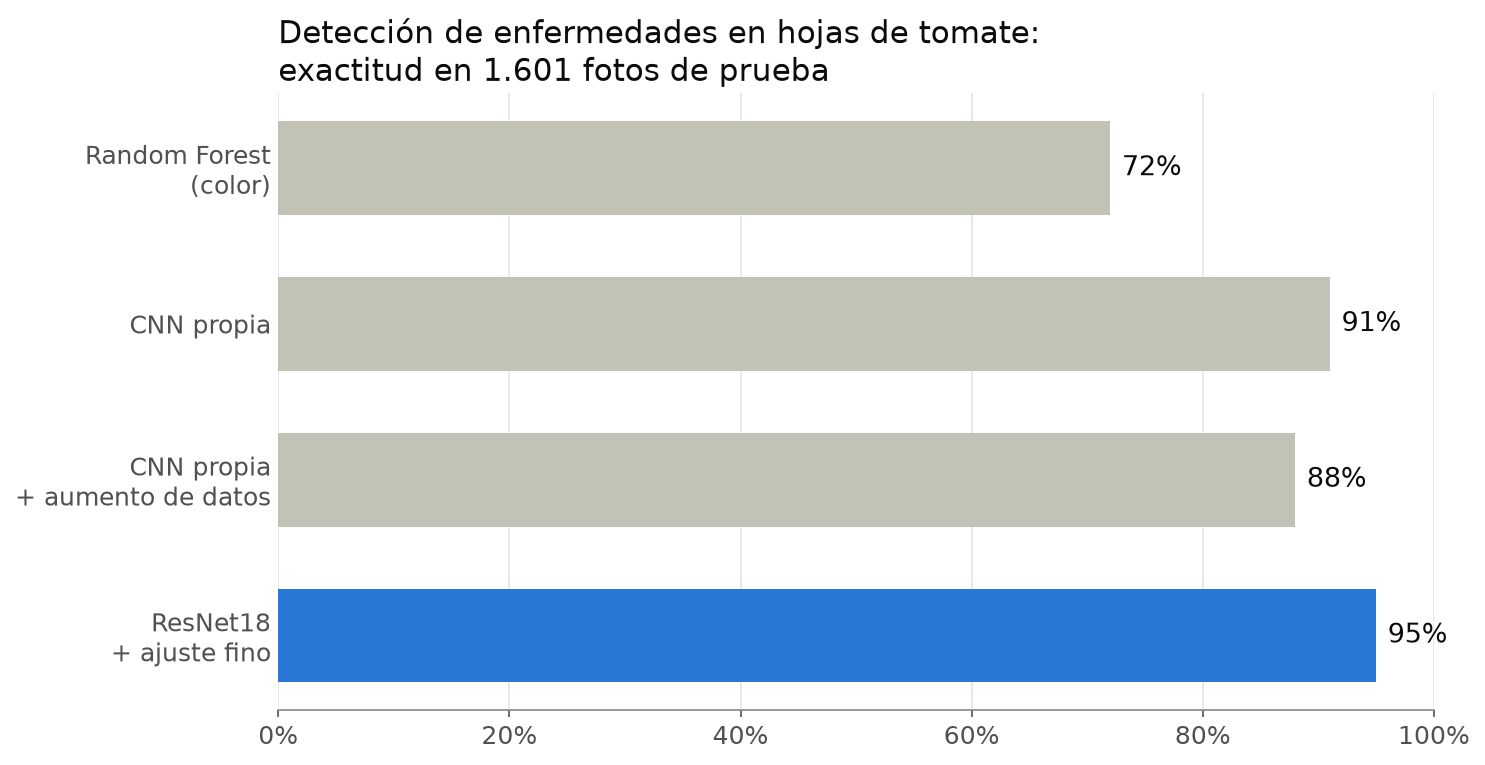

In [7]:
import matplotlib.pyplot as plt

modelos = ["Random Forest\n(color)", "CNN propia", "CNN propia\n+ aumento de datos", "ResNet18\n+ ajuste fino"]
exactitud = [0.72, 0.91, 0.88, 0.95]
colores = ["#c3c2b7", "#c3c2b7", "#c3c2b7", "#2a78d6"]

fig, ax = plt.subplots(figsize=(10, 5.2), dpi=150)
barras = ax.barh(modelos, exactitud, color=colores, height=0.6)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")

for barra, valor in zip(barras, exactitud):
    ax.text(valor + 0.01, barra.get_y() + barra.get_height() / 2, f"{valor:.0%}",
            va="center", fontsize=13, color="#0b0b0b")

ax.set_title("Detección de enfermedades en hojas de tomate:\nexactitud en 1.601 fotos de prueba",
             loc="left", fontsize=15, color="#0b0b0b")
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#898781")
ax.tick_params(colors="#52514e", labelsize=12)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("../imagenes/comparacion_modelos.png", facecolor="white")
plt.show()